# Predikčná analýza: 3 triedy závažnosti a rozdelenie 70:30

Notebook porovnáva logistickú regresiu a LightGBM pri zjednodušenej úlohe. Nadväzuje na `priprava_dat.ipynb`, ktorý musí byť spustený ako prvý.

Oproti notebooku `predikcia.ipynb` sa menia dve veci:

| | `predikcia.ipynb` | Tento notebook |
| --- | --- | --- |
| **Triedy** | `LOW`, `MEDIUM`, `HIGH`, `CRITICAL` | `LOW+MEDIUM`, `HIGH`, `CRITICAL` |
| **Rozdelenie dát** | časové, test sú roky 2020 a 2021 | náhodné 70:30, seed 67, zachovaný pomer tried |

Výstupom sú tabuľky metrík, `figures/5_f1_3_triedy.png` a `figures/6_matice_zamen_3_triedy.png`.

**Prevencia úniku informácií.** Vstupom je iba text popisu a typ CWE. Záznamy, ktorých popis priamo uvádza skóre alebo závažnosť, sú vylúčené rovnako ako v `predikcia.ipynb`.

## 1. Načítanie dát a zlúčenie tried

In [1]:
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

DATA_PATH = Path("data/processed/cve_clean.csv")
FIGURES_DIR = Path("figures")
LABELS = ["LOW+MEDIUM", "HIGH", "CRITICAL"]
CLASS_IDS = [0, 1, 2]
CRITICAL = LABELS.index("CRITICAL")
SEED = 67

LEAKAGE_PATTERN = (
    r"\bcvss(?:v?\d|:|\b)"
    r"|base score"
    r"|severity"
    r"|\brated\s+(?:as\s+)?(?:critical|high|moderate|medium|low)\b"
)

scored = pd.read_csv(DATA_PATH).dropna(subset=["severity_v3"])
has_leakage = scored["description"].str.contains(LEAKAGE_PATTERN, case=False, regex=True)
data = scored[~has_leakage].reset_index(drop=True)

data["cwe_text"] = data["cwe_ids"].fillna("")
data["target_label"] = data["severity_v3"].replace({"LOW": "LOW+MEDIUM", "MEDIUM": "LOW+MEDIUM"})
data["target"] = data["target_label"].map({label: index for index, label in enumerate(LABELS)})
assert data["target"].notna().all()
data["target"] = data["target"].astype(int)

print(f"Záznamy s CVSS v3: {len(scored)}, vylúčené pre únik cieľa: {has_leakage.sum()}, použité: {len(data)}")
data["target_label"].value_counts().reindex(LABELS).to_frame("počet")

Záznamy s CVSS v3: 92893, vylúčené pre únik cieľa: 4202, použité: 88691


,počet
target_label,
LOW+MEDIUM,36550
HIGH,38562
CRITICAL,13579


## 2. Rozdelenie dát

Dáta sú rozdelené náhodne v pomere **70 % tréning a 30 % test** so seedom 67. Parameter `stratify` zachováva pomer tried v oboch častiach.

Parametre sa vyberajú na validačnej časti, ktorá tvorí 20 % z tréningovej množiny. Testovacia množina sa do výberu nezapája. Po výbere parametrov sa model naučí na celých 70 %.

In [2]:
train_full, test = train_test_split(data, test_size=0.30, random_state=SEED, stratify=data["target"])
train, valid = train_test_split(train_full, test_size=0.20, random_state=SEED, stratify=train_full["target"])

split_summary = pd.DataFrame({
    name: part["target_label"].value_counts(normalize=True).reindex(LABELS).mul(100).round(1)
    for name, part in {"tréning 70 % %": train_full, "test 30 % %": test}.items()
})
split_summary.loc["počet záznamov"] = [len(train_full), len(test)]
display(split_summary)

seen_in_train = test["description"].isin(train_full["description"]).to_numpy()
print(f"Podiel tréningu: {len(train_full) / len(data):.3f}, podiel testu: {len(test) / len(data):.3f}")
print(f"Validačná časť z tréningu: {len(valid)}")
print(f"Testovacie záznamy s presne rovnakým popisom ako v tréningu: {seen_in_train.sum()}")

,tréning 70 % %,test 30 % %
target_label,,
LOW+MEDIUM,41.2,41.2
HIGH,43.5,43.5
CRITICAL,15.3,15.3
počet záznamov,62083.0,26608.0


Podiel tréningu: 0.700, podiel testu: 0.300
Validačná časť z tréningu: 12417
Testovacie záznamy s presne rovnakým popisom ako v tréningu: 1202


## 3. Príprava znakov

Znaky sú rovnaké ako v `predikcia.ipynb`: TF-IDF z popisu (slová a dvojice slov, najviac 30 000 položiek) a binárne príznaky typov CWE. Slovník sa učí iba z tréningových dát.

In [3]:
def make_features():
    return ColumnTransformer([
        ("text", TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=5,
            max_df=0.9,
            max_features=30_000,
            sublinear_tf=True,
        ), "description"),
        ("cwe", CountVectorizer(
            lowercase=False,
            token_pattern=r"CWE-\d+",
            binary=True,
        ), "cwe_text"),
    ])

def to_float32(matrix):
    return sparse.csr_matrix(matrix, dtype=np.float32)

tuning_features = make_features()
X_train = to_float32(tuning_features.fit_transform(train))
X_valid = to_float32(tuning_features.transform(valid))
y_train, y_valid = train["target"].to_numpy(), valid["target"].to_numpy()
print("Rozmer matice pri ladení:", X_train.shape)

Rozmer matice pri ladení: (49666, 30275)


## 4. Výber parametrov

Parametre sa vyberajú podľa macro F1 na validačnej časti.

In [4]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=CLASS_IDS, zero_division=0)

def make_logreg(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000, random_state=SEED)

logreg_results = []
for C in [0.3, 1, 3, 10]:
    model = make_logreg(C).fit(X_train, y_train)
    logreg_results.append({"C": C, "macro F1": macro_f1(y_valid, model.predict(X_valid))})

logreg_results = pd.DataFrame(logreg_results).round(4)
best_C = logreg_results.loc[logreg_results["macro F1"].idxmax(), "C"]
display(logreg_results)
print("Najlepšie C:", best_C)

,C,macro F1
0,0.3,0.7002
1,1.0,0.7208
2,3.0,0.7275
3,10.0,0.7224


Najlepšie C: 3.0


In [5]:
def make_lightgbm(num_leaves, n_estimators):
    return lgb.LGBMClassifier(
        objective="multiclass",
        class_weight="balanced",
        n_estimators=n_estimators,
        learning_rate=0.1,
        num_leaves=num_leaves,
        min_child_samples=20,
        colsample_bytree=0.3,
        subsample=0.8,
        subsample_freq=1,
        random_state=SEED,
        deterministic=True,
        force_row_wise=True,
        n_jobs=4,
        verbosity=-1,
    )

lightgbm_results = []
for num_leaves in [31, 63]:
    model = make_lightgbm(num_leaves, n_estimators=500)
    model.fit(
        X_train, y_train,
        eval_X=X_valid,
        eval_y=y_valid,
        eval_metric="multi_logloss",
        callbacks=[lgb.early_stopping(30, verbose=False)],
    )
    lightgbm_results.append({
        "num_leaves": num_leaves,
        "počet stromov": model.best_iteration_,
        "macro F1": macro_f1(y_valid, model.predict(X_valid)),
    })

lightgbm_results = pd.DataFrame(lightgbm_results).round(4)
best_lightgbm = lightgbm_results.loc[lightgbm_results["macro F1"].idxmax()]
best_leaves, best_trees = int(best_lightgbm["num_leaves"]), int(best_lightgbm["počet stromov"])
display(lightgbm_results)
print("Najlepšie num_leaves:", best_leaves, "počet stromov:", best_trees)

,num_leaves,počet stromov,macro F1
0,31,428,0.7269
1,63,277,0.7341


Najlepšie num_leaves: 63 počet stromov: 277


## 5. Záverečné učenie a vyhodnotenie

Modely sa naučia na celej 70 % časti a vyhodnotia sa na 30 % testovacích dát. MAE sa počíta na poradí tried: `LOW+MEDIUM` = 0, `HIGH` = 1, `CRITICAL` = 2.

In [6]:
final_features = make_features()
X_full = to_float32(final_features.fit_transform(train_full))
X_test = to_float32(final_features.transform(test))
y_full, y_test = train_full["target"].to_numpy(), test["target"].to_numpy()

models = {
    "Triviálny model": DummyClassifier(strategy="most_frequent"),
    "Logistická regresia": make_logreg(best_C),
    "LightGBM": make_lightgbm(best_leaves, best_trees),
}

predictions, fit_seconds = {}, {}
for name, model in models.items():
    started = time.perf_counter()
    model.fit(X_full, y_full)
    fit_seconds[name] = time.perf_counter() - started
    predictions[name] = model.predict(X_test)

def evaluate(y_true, y_pred):
    precision, recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[CRITICAL], zero_division=0
    )
    return {
        "Macro F1": macro_f1(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Vážené F1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "MAE poradia": mean_absolute_error(y_true, y_pred),
        "Recall CRITICAL": recall[0],
        "Precision CRITICAL": precision[0],
    }

metrics = pd.DataFrame({name: evaluate(y_test, pred) for name, pred in predictions.items()}).T
metrics["Tréning (s)"] = pd.Series(fit_seconds)
metrics.round(3)

,Macro F1,Accuracy,Vážené F1,MAE poradia,Recall CRITICAL,Precision CRITICAL,Tréning (s)
Triviálny model,0.202,0.435,0.264,0.565,0.000,0.000,0.001
Logistická regresia,0.730,0.747,0.748,0.279,0.764,0.576,4.515
LightGBM,0.740,0.756,0.757,0.270,0.772,0.592,58.670


In [7]:
per_class = pd.concat({
    name: pd.DataFrame(
        precision_recall_fscore_support(y_test, predictions[name], labels=CLASS_IDS, zero_division=0)[:3],
        index=["precision", "recall", "F1"],
        columns=LABELS,
    ).T
    for name in ["Logistická regresia", "LightGBM"]
})
display(per_class.round(3))

# Spoľahlivosť rozdielu: bootstrap testovacej množiny
def critical_recall(y_true, y_pred):
    return (y_pred[y_true == CRITICAL] == CRITICAL).mean()

rng = np.random.default_rng(SEED)
differences = {"macro F1": [], "accuracy": [], "recall CRITICAL": []}
for _ in range(300):
    sample = rng.integers(0, len(y_test), len(y_test))
    y_sample = y_test[sample]
    pred_lightgbm = predictions["LightGBM"][sample]
    pred_logreg = predictions["Logistická regresia"][sample]
    differences["macro F1"].append(macro_f1(y_sample, pred_lightgbm) - macro_f1(y_sample, pred_logreg))
    differences["accuracy"].append((pred_lightgbm == y_sample).mean() - (pred_logreg == y_sample).mean())
    differences["recall CRITICAL"].append(critical_recall(y_sample, pred_lightgbm) - critical_recall(y_sample, pred_logreg))

for metric, values in differences.items():
    low, high = np.percentile(values, [2.5, 97.5])
    print(f"Rozdiel {metric} (LightGBM mínus logistická regresia): {np.mean(values):.4f}, 95 % interval [{low:.4f}, {high:.4f}]")

precision  recall     F1
Logistická regresia LOW+MEDIUM      0.811   0.807  0.809
                    HIGH            0.768   0.684  0.723
                    CRITICAL        0.576   0.764  0.657
LightGBM            LOW+MEDIUM      0.817   0.810  0.813
                    HIGH            0.776   0.699  0.736
                    CRITICAL        0.592   0.772  0.670

Rozdiel macro F1 (LightGBM mínus logistická regresia): 0.0098, 95 % interval [0.0053, 0.0137]
Rozdiel accuracy (LightGBM mínus logistická regresia): 0.0092, 95 % interval [0.0050, 0.0127]
Rozdiel recall CRITICAL (LightGBM mínus logistická regresia): 0.0081, 95 % interval [-0.0033, 0.0179]


### Kontrola: testovacie záznamy s novým popisom

Pri náhodnom rozdelení sa môže rovnaký popis objaviť v tréningu aj v teste. Tabuľka ukazuje výsledky iba na záznamoch, ktorých presný popis model pri učení nevidel.

In [8]:
unseen = ~seen_in_train
pd.DataFrame({
    name: evaluate(y_test[unseen], predictions[name][unseen])
    for name in ["Logistická regresia", "LightGBM"]
}).T.round(3)

,Macro F1,Accuracy,Vážené F1,MAE poradia,Recall CRITICAL,Precision CRITICAL
Logistická regresia,0.725,0.742,0.744,0.285,0.758,0.574
LightGBM,0.735,0.751,0.753,0.275,0.767,0.589


## 6. Vizualizácie výsledkov

In [9]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
MODEL_COLORS = {"Logistická regresia": "#2a78d6", "LightGBM": "#eb6834"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})
FIGURES_DIR.mkdir(exist_ok=True)

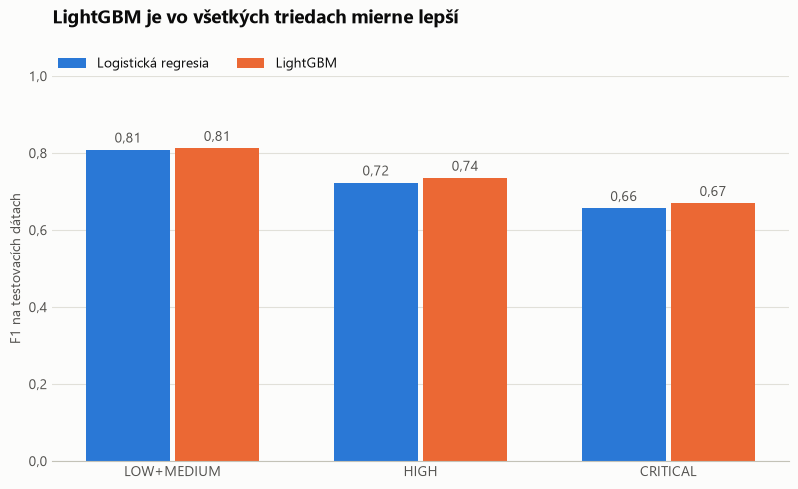

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 5))
positions = np.arange(len(LABELS))
width = 0.36

for offset, name in zip((-width / 2, width / 2), MODEL_COLORS):
    values = per_class.loc[name, "F1"].reindex(LABELS).to_numpy()
    bars = ax.bar(positions + offset, values, width - 0.02, color=MODEL_COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{value:.2f}".replace(".", ",") for value in values],
                 padding=3, color=INK_SECONDARY)

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_xticks(positions, LABELS)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.1f}".replace(".", ","))
ax.set_ylabel("F1 na testovacích dátach")
ax.set_title('LightGBM je vo všetkých triedach mierne lepší', loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(ncols=2, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0)

fig.savefig(FIGURES_DIR / "5_f1_3_triedy.png")
plt.show()

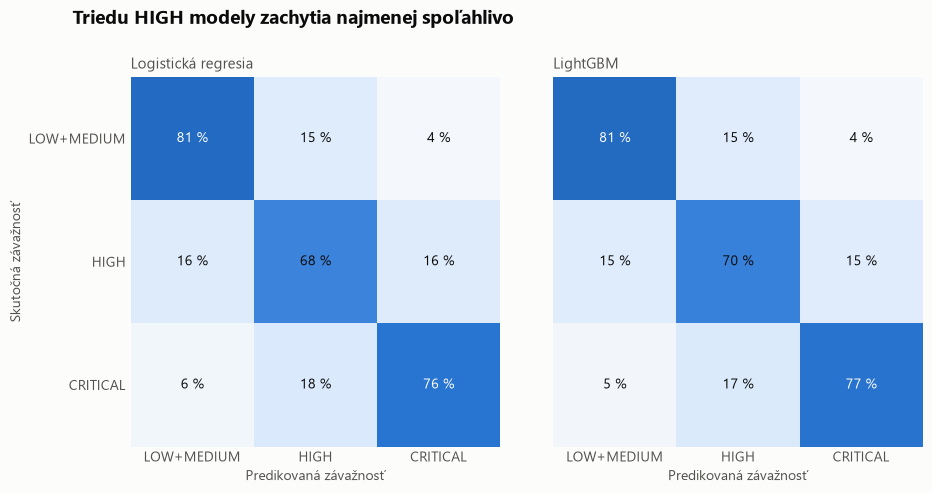

In [11]:
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharey=True, gridspec_kw={"wspace": 0.08})

for ax, name in zip(axes, MODEL_COLORS):
    matrix = confusion_matrix(y_test, predictions[name], labels=CLASS_IDS, normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for row in CLASS_IDS:
        for column in CLASS_IDS:
            value = matrix[row, column]
            ax.text(column, row, f"{value * 100:.0f} %", ha="center", va="center",
                    color="#ffffff" if value >= 0.75 else INK)
    ax.set_title(name, loc="left", fontsize=11, color=INK_SECONDARY)
    ax.set_xticks(CLASS_IDS, LABELS)
    ax.set_yticks(CLASS_IDS, LABELS)
    ax.set_xlabel("Predikovaná závažnosť")
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)

axes[0].set_ylabel("Skutočná závažnosť")
fig.suptitle('Triedu HIGH modely zachytia najmenej spoľahlivo', x=0.08, y=1.02, ha="left", fontsize=14, fontweight="bold")

fig.savefig(FIGURES_DIR / "6_matice_zamen_3_triedy.png")
plt.show()

## 7. Zhrnutie

Výsledky platia pre testovaciu množinu 26 608 zraniteľností, teda 30 % z 88 691 použitých záznamov. Tréningová množina má 62 083 záznamov.

| Metrika | Triviálny model | Logistická regresia | LightGBM |
| --- | ---: | ---: | ---: |
| Macro F1 | 0,202 | 0,730 | 0,740 |
| Accuracy | 0,435 | 0,747 | 0,756 |
| Vážené F1 | 0,264 | 0,748 | 0,757 |
| MAE poradia | 0,565 | 0,279 | 0,270 |
| Recall `CRITICAL` | 0,000 | 0,764 | 0,772 |
| Precision `CRITICAL` | 0,000 | 0,576 | 0,592 |
| Čas tréningu | menej ako 1 s | asi 5 s | asi 1 min |

**Vyhodnotenie:**

- LightGBM je spoľahlivo, no len mierne lepší. Rozdiel macro F1 je 0,010 s 95 % intervalom [0,005; 0,014] a rozdiel accuracy je 0,009 s intervalom [0,005; 0,013].
- Rozdiel v recalle triedy `CRITICAL` je 0,008 a jeho interval [-0,003; 0,018] obsahuje nulu, takže v zachytávaní kritických zraniteľností nie je preukázateľný.
- Logistická regresia je výrazne rýchlejšia a dosahuje takmer rovnaký výsledok.
- Najväčšiu časť záznamov zaradia modely správne pri triede `LOW+MEDIUM`, recall je približne 0,81. Pri triede `HIGH` je približne 0,68 až 0,70.

**Porovnanie s notebookom `predikcia.ipynb` (LightGBM):**

| | 4 triedy, časové rozdelenie | 3 triedy, náhodné 70:30 |
| --- | ---: | ---: |
| Macro F1 | 0,508 | 0,740 |
| Accuracy | 0,647 | 0,756 |

Zlepšenie **neznamená, že sa model stal lepším**. Úloha je ľahšia, lebo najslabšia trieda bola zlúčená s `MEDIUM`, a náhodné rozdelenie je ľahšie než predikcia budúcich rokov. Tieto dva vplyvy sa z uvedených behov nedajú oddeliť. MAE sa medzi notebookmi neporovnáva, lebo stupnice majú rôzny počet tried.

**Obmedzenia:**

- Náhodné rozdelenie miesi staré a nové zraniteľnosti, takže výsledok pravdepodobne nadhodnocuje úspešnosť na budúcich dátach.
- 1 202 testovacích záznamov má presne rovnaký popis ako niektorý tréningový záznam. Bez nich je macro F1 0,725 pre logistickú regresiu a 0,735 pre LightGBM. Podobné, no nie identické popisy v teste zostávajú.
- Precision `CRITICAL` je približne 0,58 až 0,59, takže asi 4 z 10 označených zraniteľností v skutočnosti kritické nie sú.
- Zlúčená trieda spája `LOW` a `MEDIUM`, model teda tieto dve úrovne nerozlišuje.